# 예측 모델 0~3단계 (A · 강민주)

노션 '분석 설계 8.3'의 단계별 모델 가운데 날씨를 넣기 전까지를 비교한다. Train(2022~23 · 2023~24 겨울, 2023 · 2024 여름)으로 학습하고 Dev(2024~25 겨울, 2025 여름)로만 평가한다. Test는 열지 않는다.

| 단계 | 모델 | 입력 |
| --- | --- | --- |
| 0 | 평소값 (비율 = 1) | 없음 |
| 1 | 직전 상태 유지 (y_hat = ratio_t0) | t 시점 비율 |
| 2 | 선형회귀 | (1) 도로 (2) 시간 (3) 최근 상태 |
| 3 | CatBoost | 같은 입력, 날씨 없음 |

계산은 `src/analysis/prediction.py`가 하고, 이 노트북은 저장된 결과(`outputs/tables/prediction_dev_metrics.csv`, `logs/kmj/prediction/prediction.json`)를 읽어서 보여 준다. MAE 분 = |y_hat - y| x 입력용 평소 통행시간 / 60.

In [1]:
RUN_BUILD = False  # True로 바꿀 때만 학습 · 평가를 다시 돌려 결과 파일을 덮어쓴다 (몇 분 걸림)

import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == '02_analysis' else Path.cwd()
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 한글 글꼴
plt.rcParams['axes.unicode_minus'] = False

if RUN_BUILD:
    subprocess.run([sys.executable, str(ROOT / 'src' / 'analysis' / 'prediction.py')], check=True, cwd=ROOT)
else:
    print('RUN_BUILD = False (저장된 결과를 읽기만)')

m = pd.read_csv(ROOT / 'outputs' / 'tables' / 'prediction_dev_metrics.csv')
log = json.loads((ROOT / 'logs' / 'kmj' / 'prediction' / 'prediction.json').read_text(encoding='utf-8'))
print('실행:', log['run_at'], '| 행 수:', log['rows'], '| 정답 빈 행 제외:', log['dropped_no_target'])

RUN_BUILD = False (저장된 결과를 읽기만)
실행: 2026-11-27T11:03:54+09:00 | 행 수: {'train': 592972, 'dev': 291296, 'train_seasons': ['2022-23_winter', '2023-24_winter', '2023_summer', '2024_summer'], 'dev_seasons': ['2024-25_winter', '2025_summer']} | 정답 빈 행 제외: 1332


## 1. 전체 (Dev)

주 지표는 h = 3 MAE(분).

In [2]:
cols = ['stage', 'horizon', 'n_rows', 'mae_min', 'rmse_min', 'mae_ratio', 'rmse_ratio']
m.query("group_type == '전체'")[cols].round(3)

,stage,horizon,n_rows,mae_min,rmse_min,mae_ratio,rmse_ratio
0,0_평소값,전체,291296,1.481,3.260,0.082,0.153
11,0_평소값,1,145648,1.481,3.260,0.082,0.153
22,0_평소값,3,145648,1.481,3.260,0.082,0.153
33,1_직전상태,전체,291296,1.250,2.570,0.075,0.137
44,1_직전상태,1,145648,1.087,2.129,0.067,0.122
55,1_직전상태,3,145648,1.414,2.945,0.083,0.150
66,2_선형회귀,전체,291296,1.160,2.430,0.068,0.126
77,2_선형회귀,1,145648,1.022,2.039,0.062,0.113
88,2_선형회귀,3,145648,1.297,2.766,0.075,0.138
99,3_CatBoost,전체,291296,1.087,2.336,0.065,0.123


## 2. 날씨 구분별 (h = 3)

시간 수 = 겹치지 않는 (날짜, 목표 시각) 수. 악천후 · 약한 비·눈은 시간 수가 적어 차이를 크게 읽지 않는다.

In [3]:
w = m.query("group_type == '날씨' and horizon == '3'")
w.pivot(index='stage', columns='group', values='mae_min').round(3)

group,맑음,악천후,약한 비·눈
stage,,,
0_평소값,1.276,2.650,1.685
1_직전상태,1.257,2.312,1.552
2_선형회귀,1.139,2.207,1.421
3_CatBoost,1.046,2.075,1.390


In [4]:
w.drop_duplicates('group')[['group', 'n_rows', 'n_hours']]

,group,n_rows,n_hours
23,맑음,117407,653
24,악천후,19066,106
25,약한 비·눈,9175,51


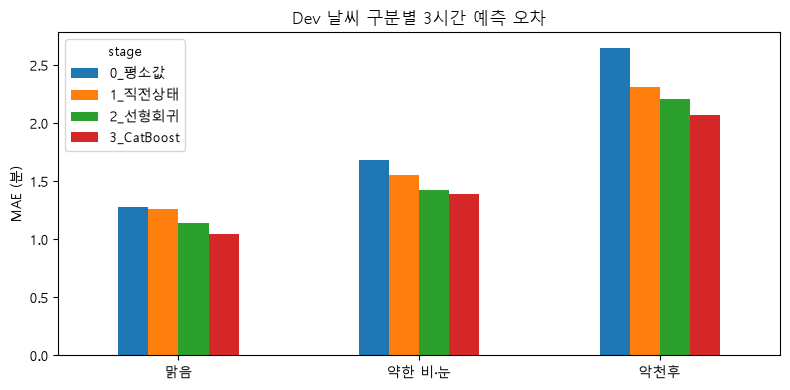

In [5]:
ax = w.pivot(index='group', columns='stage', values='mae_min').loc[['맑음', '약한 비·눈', '악천후']].plot.bar(rot=0, figsize=(8, 4))
ax.set_ylabel('MAE (분)')
ax.set_xlabel('')
ax.set_title('Dev 날씨 구분별 3시간 예측 오차')
plt.tight_layout()

## 3. 나눠 보기 (h = 3): 눈 · 비, 계절, 출퇴근, 평소값 대체

In [6]:
for gtype in ['눈비', '계절', '출퇴근', '평소값']:
    t = m.query("group_type == @gtype and horizon == '3'")
    print(f'[{gtype}]')
    display(t.pivot(index='stage', columns='group', values='mae_min').round(3))
    display(t.drop_duplicates('group')[['group', 'n_rows', 'n_hours']])

[눈비]


group,눈,비
stage,,
0_평소값,2.835,2.154
1_직전상태,2.616,1.864
2_선형회귀,2.501,1.751
3_CatBoost,2.395,1.654


,group,n_rows,n_hours
26,눈,7550,42
27,비,20691,115


[계절]


group,summer,winter
stage,,
0_평소값,1.444,1.533
1_직전상태,1.387,1.451
2_선형회귀,1.262,1.347
3_CatBoost,1.169,1.250


,group,n_rows,n_hours
28,summer,85467,475
29,winter,60181,335


... (2 outputs left out)

,group,n_rows,n_hours
30,출근,58279,324
31,퇴근,87369,486


[평소값]


group,28일
stage,
0_평소값,1.481
1_직전상태,1.414
2_선형회귀,1.297
3_CatBoost,1.203


,group,n_rows,n_hours
32,28일,145648,810


## 4. CatBoost 변수 중요도 (3단계)

In [7]:
pd.Series(log['catboost_importance']).rename('중요도').to_frame()

,중요도
ratio_t0,24.62
type_ratio_t0,12.03
city_ratio_t0,11.55
target_hour,8.33
total_distance_m,7.09
lanes,6.97
month,5.90
weekday,5.70
horizon,4.22
function_type,2.54
